In [1]:
import numpy as np
import pandas as pd
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from modules.benchmark import *
import plotly.express as px

In [2]:
avalon = load_cleaned()
avalon = drop_rheological(avalon)
avalon = add_avalon(avalon, columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
X, y, groups = xy_split(avalon)
X = drop_smiles(X)

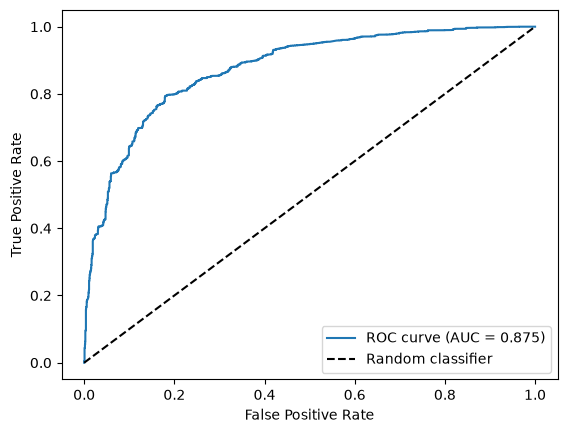

In [3]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        random_state=42,
        verbosity=-1
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [4]:
y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')

In [5]:
confidence_error = np.abs(y.to_numpy() - y_proba[:, 1])
confidence_error[:10]

array([0.07668942, 0.04850185, 0.00969231, 0.00598257, 0.01077884,
       0.0115492 , 0.01224476, 0.00819543, 0.25903366, 0.10192891])

In [6]:
confidence = pd.concat([avalon, pd.DataFrame(confidence_error, columns=['confidence_error'])], axis=1)

In [7]:
fig = px.histogram(data_frame=confidence, x="confidence_error", title="Confidence error Distribution")
fig.update_traces(
    xbins=dict(
        start=0.0,
        end=1.0,
        size=0.05,
    )
)
fig.show()

In [8]:
filtered = confidence[confidence['confidence_error']  > 0.95].sort_values(by='confidence_error', ascending=False)
filtered[['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2', 'confidence_error']]

,smiles_surfactant1,smiles_surfactant2,smiles_additive1,smiles_additive2,confidence_error
500,CCCCCCCCCCCCCCCC[n+]1ccccc1.[Cl-],NaN,[Cl-].[Na+],O=C([O-])c1ccccc1O.[Na+],0.999950
501,CCCCCCCCCCCCCCCC[n+]1ccccc1.[Cl-],NaN,[Cl-].[Na+],O=C([O-])c1ccccc1O.[Na+],0.999950
485,CCCCCCCCCCCCCCCC[n+]1ccccc1.[Cl-],NaN,[Cl-].[Na+],O=C([O-])c1ccccc1O.[Na+],0.999823
484,CCCCCCCCCCCCCCCC[n+]1ccccc1.[Cl-],NaN,[Cl-].[Na+],O=C([O-])c1ccccc1O.[Na+],0.999823
11,CCCCCCCCCCCCCC[N+](C)(C)CCCS(=O)(=O)[O-],CCCCCCCCCCCCOS(=O)(=O)[O-].[Na+],NaN,NaN,0.999788
...,...,...,...,...,...
7098,CCCCCCCCCCCCCCCC(=O)NCCC[N+](C)(C)CCCS(=O)(=O)...,NaN,[Cl-].[Na+],NaN,0.951253
7867,CCCCCCCCCCCCOS(=O)(=O)[O-].[Na+],NaN,[Br-].[Na+],NaN,0.950702
7095,CCCCCCCCCCCCCCCC(=O)NCCC[N+](C)(C)CCCS(=O)(=O)...,NaN,[Cl-].[Na+],NaN,0.950289
7096,CCCCCCCCCCCCCCCC(=O)NCCC[N+](C)(C)CCCS(=O)(=O)...,NaN,[Cl-].[Na+],NaN,0.950289
